In [63]:

# 1. Data manipulation
import pandas as pd
import numpy as np

# 2. Machine Learning
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    silhouette_score
)

# 3. NLP - Natural Language Processing
import nltk
import spacy

# 4. Statistical analysis and time series
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose

# 5. Time-series forecasting
from prophet import Prophet

# 6. Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 7. SQL database connection
from sqlalchemy import create_engine

print("All ML libraries imported successfully!")


All ML libraries imported successfully!


In [64]:

!git config --global user.name "Sneha"
!git config --global user.email "sneha.s@nineleaps.com"


In [65]:

# Configure Git identity
!git config --global user.name "Sneha"
!git config --global user.email "sneha.s@nineleaps.com"

# Create project folder
import os

os.makedirs("uber_eats_ml_case_study/data/raw", exist_ok=True)
os.makedirs("uber_eats_ml_case_study/data/processed", exist_ok=True)
os.makedirs("uber_eats_ml_case_study/scripts", exist_ok=True)
os.makedirs("uber_eats_ml_case_study/notebooks", exist_ok=True)
os.makedirs("uber_eats_ml_case_study/docs", exist_ok=True)
os.makedirs("uber_eats_ml_case_study/models", exist_ok=True)
os.makedirs("uber_eats_ml_case_study/outputs", exist_ok=True)

print("Project folders created successfully!")


Project folders created successfully!


In [66]:

!git init
!git switch -c feature/uber-eats-pipeline
!git config --global user.name
!git config --global user.email


Reinitialized existing Git repository in /home/nineleaps/Documents/ml_uber/uber_eats_ml_case_study/.git/
Switched to a new branch 'feature/uber-eats-pipeline'
Sneha
sneha.s@nineleaps.com


In [67]:
import os
import shutil
import sys

print("Python executable:", sys.executable)
print("Git location:", shutil.which("git"))
print("Current directory:", os.getcwd())

Python executable: /home/nineleaps/Documents/ml_uber/.venv-1/bin/python
Git location: /usr/bin/git
Current directory: /home/nineleaps/Documents/ml_uber/uber_eats_ml_case_study


In [68]:
!git --version
!which git

git version 2.43.0
/usr/bin/git


In [69]:
import os
import shutil

os.environ["PATH"] = "/usr/bin:/bin:" + os.environ.get("PATH", "")

print("Git location:", shutil.which("git"))
!git --version

Git location: /usr/bin/git
git version 2.43.0


In [70]:
import os

print("Current directory:", os.getcwd())
print("Project files:", os.listdir())

Current directory: /home/nineleaps/Documents/ml_uber/uber_eats_ml_case_study
Project files: ['notebooks', '.gitignore', 'models', 'outputs', 'docs', '.git', 'data', 'scripts', 'uber_eats_ml_case_study', 'README.md']


In [71]:

!git config --global user.name "Sneha"
!git config --global user.email "sneha.s@nineleaps.com"

!git config --global user.name
!git config --global user.email

Sneha
sneha.s@nineleaps.com


In [72]:
!git init

Reinitialized existing Git repository in /home/nineleaps/Documents/ml_uber/uber_eats_ml_case_study/.git/


In [73]:
!git switch -c feature/uber-eats-pipeline

Switched to a new branch 'feature/uber-eats-pipeline'


In [74]:
!git branch --show-current
!git status

feature/uber-eats-pipeline
On branch feature/uber-eats-pipeline

No commits yet

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.gitignore
	README.md
	data/
	scripts/

nothing added to commit but untracked files present (use "git add" to track)


In [75]:
import os

folders = [
    "data/raw",
    "data/processed",
    "scripts",
    "notebooks",
    "docs",
    "models",
    "outputs"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

for folder in folders:
    print(folder)

Project folders created successfully!
data/raw
data/processed
scripts
notebooks
docs
models
outputs


In [76]:
readme_content = """# Uber Eats ML Case Study

## Project Overview
Analyze food-delivery operations using synthetic data and machine learning.

## Objectives
- Generate synthetic datasets.
- Perform ETL and exploratory data analysis.
- Identify factors affecting delivery time.
- Prepare data for machine learning.

## Technologies
Python, Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn, Git.

## Datasets
Customers, restaurants, drivers, orders, deliveries, payments, and reviews.

## Data Generation
Run `python scripts/generate_data.py` from the project root.

## Disclaimer
All datasets are synthetic and intended for educational purposes.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [77]:
gitignore_content = """__pycache__/
*.py[cod]
.venv/
venv/
.ipynb_checkpoints/
.env
.DS_Store
"""

with open(".gitignore", "w", encoding="utf-8") as file:
    file.write(gitignore_content)

print(".gitignore created successfully!")

.gitignore created successfully!


In [78]:
%pip install pandas numpy

Note: you may need to restart the kernel to use updated packages.


In [2]:

%%writefile scripts/generate_data.py
import os
import numpy as np
import pandas as pd

np.random.seed(42)

OUTPUT_DIR = "data/raw"
os.makedirs(OUTPUT_DIR, exist_ok=True)

NUM_CUSTOMERS = 1000
NUM_RESTAURANTS = 100
NUM_DRIVERS = 150
NUM_ORDERS = 5000

CITIES = ["Bengaluru", "Mumbai", "Delhi", "Hyderabad", "Pune"]

# 1. Customers
customers = pd.DataFrame({
    "customer_id": [f"C{i:04d}" for i in range(1, NUM_CUSTOMERS + 1)],
    "age": np.random.randint(18, 71, NUM_CUSTOMERS),
    "gender": np.random.choice(
        ["Female", "Male", "Other"], NUM_CUSTOMERS,
        p=[0.48, 0.48, 0.04]
    ),
    "city": np.random.choice(CITIES, NUM_CUSTOMERS),
    "signup_date": pd.to_datetime(
        np.random.choice(
            pd.date_range("2023-01-01", "2025-12-31"),
            NUM_CUSTOMERS
        )
    )
})

# 2. Restaurants
restaurants = pd.DataFrame({
    "restaurant_id": [f"R{i:03d}" for i in range(1, NUM_RESTAURANTS + 1)],
    "restaurant_name": [
        f"Restaurant_{i:03d}" for i in range(1, NUM_RESTAURANTS + 1)
    ],
    "category": np.random.choice(
        ["Indian", "Chinese", "Italian", "Fast Food", "Healthy", "Desserts"],
        NUM_RESTAURANTS
    ),
    "restaurant_rating": np.round(
        np.random.uniform(2.5, 5.0, NUM_RESTAURANTS), 1
    ),
    "prep_time_minutes": np.random.randint(10, 41, NUM_RESTAURANTS),
    "city": np.random.choice(CITIES, NUM_RESTAURANTS)
})

# 3. Drivers
drivers = pd.DataFrame({
    "driver_id": [f"D{i:03d}" for i in range(1, NUM_DRIVERS + 1)],
    "vehicle_type": np.random.choice(
        ["Bike", "Scooter", "Car"], NUM_DRIVERS,
        p=[0.25, 0.60, 0.15]
    ),
    "driver_rating": np.round(
        np.random.uniform(3.0, 5.0, NUM_DRIVERS), 1
    ),
    "experience_months": np.random.randint(1, 73, NUM_DRIVERS)
})

# 4. Orders
order_ids = [f"O{i:05d}" for i in range(1, NUM_ORDERS + 1)]

order_timestamps = pd.to_datetime(
    np.random.choice(
        pd.date_range("2025-01-01", "2025-12-31 23:00:00", freq="h"),
        NUM_ORDERS
    )
)

order_amounts = np.round(
    np.random.uniform(150, 1500, NUM_ORDERS), 2
)

tip_amounts = np.round(
    order_amounts * np.random.uniform(0, 0.20, NUM_ORDERS), 2
)

orders = pd.DataFrame({
    "order_id": order_ids,
    "customer_id": np.random.choice(customers["customer_id"], NUM_ORDERS),
    "restaurant_id": np.random.choice(restaurants["restaurant_id"], NUM_ORDERS),
    "order_timestamp": order_timestamps,
    "order_amount": order_amounts,
    "tip_amount": tip_amounts,
    "weather": np.random.choice(
        ["Clear", "Rainy", "Cloudy", "Stormy"], NUM_ORDERS,
        p=[0.50, 0.20, 0.25, 0.05]
    ),
    "traffic_condition": np.random.choice(
        ["Low", "Medium", "High"], NUM_ORDERS,
        p=[0.30, 0.45, 0.25]
    ),
    "order_status": np.random.choice(
        ["Delivered", "Cancelled", "Preparing", "On the Way"],
        NUM_ORDERS, p=[0.90, 0.05, 0.02, 0.03]
    )
})

# 5. Deliveries
prep_lookup = restaurants.set_index("restaurant_id")["prep_time_minutes"]
prep_time = orders["restaurant_id"].map(prep_lookup).to_numpy()

distance = np.round(np.random.uniform(1, 15, NUM_ORDERS), 2)

traffic_delay = orders["traffic_condition"].map({
    "Low": 0, "Medium": 8, "High": 18
}).to_numpy()

weather_delay = orders["weather"].map({
    "Clear": 0, "Cloudy": 3, "Rainy": 10, "Stormy": 20
}).to_numpy()

base_delivery_time = (
    prep_time + distance * 3 + traffic_delay + weather_delay
)

random_variation = np.random.normal(
    loc=0, scale=5, size=NUM_ORDERS
)

delivery_minutes = np.maximum(
    10, base_delivery_time + random_variation
).round().astype(int)

delivery_status = orders["order_status"].map({
    "Delivered": "Delivered",
    "Cancelled": "Cancelled",
    "Preparing": "Pending",
    "On the Way": "In Transit"
})

deliveries = pd.DataFrame({
    "delivery_id": [f"DL{i:05d}" for i in range(1, NUM_ORDERS + 1)],
    "order_id": order_ids,
    "driver_id": np.random.choice(drivers["driver_id"], NUM_ORDERS),
    "delivery_distance_km": distance,
    "preparation_time_minutes": prep_time,
    "delivery_time_minutes": np.where(
        orders["order_status"].eq("Delivered"),
        delivery_minutes, np.nan
    ),
    "delivery_status": delivery_status
})

# 6. Payments
payment_statuses = np.random.choice(
    ["Completed", "Failed", "Pending", "Refunded"],
    NUM_ORDERS,
    p=[0.88, 0.04, 0.03, 0.05]
)

# Cancelled orders are refunded in this synthetic dataset
payment_statuses = np.where(
    orders["order_status"].eq("Cancelled"),
    "Refunded",
    payment_statuses
)

payments = pd.DataFrame({
    "payment_id": [f"P{i:05d}" for i in range(1, NUM_ORDERS + 1)],
    "order_id": order_ids,
    "payment_method": np.random.choice(
        ["Card", "UPI", "Cash", "Wallet"], NUM_ORDERS
    ),
    "payment_status": payment_statuses,
    "payment_amount": np.round(
        orders["order_amount"] + orders["tip_amount"], 2
    )
})

# 7. Reviews: only delivered orders can receive reviews
delivered_ids = orders.loc[
    orders["order_status"].eq("Delivered"), "order_id"
].to_numpy()

review_count = int(len(delivered_ids) * 0.35)

reviewed_ids = np.random.choice(
    delivered_ids, review_count, replace=False
)

review_texts = [
    "Fast delivery and tasty food",
    "Food was good but delivery was slow",
    "Excellent experience",
    "Order arrived late",
    "Packaging could be improved",
    "Great restaurant and service"
]

review_order_timestamps = (
    orders.set_index("order_id")
    .loc[reviewed_ids, "order_timestamp"]
    .reset_index(drop=True)
)

reviews = pd.DataFrame({
    "review_id": [f"RV{i:05d}" for i in range(1, review_count + 1)],
    "order_id": reviewed_ids,
    "review_rating": np.random.randint(1, 6, review_count),
    "review_text": np.random.choice(review_texts, review_count),
    "review_timestamp": (
        review_order_timestamps
        + pd.to_timedelta(
            np.random.randint(1, 49, review_count), unit="h"
        )
    )
})

# Save all seven datasets
datasets = {
    "customers": customers,
    "restaurants": restaurants,
    "drivers": drivers,
    "orders": orders,
    "deliveries": deliveries,
    "payments": payments,
    "reviews": reviews
}

for name, df in datasets.items():
    file_path = os.path.join(OUTPUT_DIR, f"{name}.csv")
    df.to_csv(file_path, index=False)
    print(f"{name}.csv: {df.shape[0]} rows, {df.shape[1]} columns")

print("\nAll seven synthetic datasets generated successfully!")


Writing scripts/generate_data.py


FileNotFoundError: [Errno 2] No such file or directory: 'scripts/generate_data.py'

In [80]:
%run scripts/generate_data.py

customers.csv: 1000 rows, 5 columns
restaurants.csv: 100 rows, 6 columns
drivers.csv: 150 rows, 4 columns
orders.csv: 5000 rows, 9 columns
deliveries.csv: 5000 rows, 7 columns
payments.csv: 5000 rows, 5 columns
reviews.csv: 1573 rows, 5 columns

All seven synthetic datasets generated successfully!


In [81]:
import os

print("Current working directory:", os.getcwd())
print("Raw folder exists:", os.path.exists("data/raw"))
print("Raw folder contents:", os.listdir("data/raw") if os.path.exists("data/raw") else "Folder not found")
print("Script exists:", os.path.exists("scripts/generate_data.py"))

Current working directory: /home/nineleaps/Documents/ml_uber/uber_eats_ml_case_study
Raw folder exists: True
Raw folder contents: ['restaurants.csv', 'orders.csv', 'customers.csv', 'drivers.csv', 'deliveries.csv', 'payments.csv', 'reviews.csv']
Script exists: True


In [82]:
import pandas as pd
import os

DATA_DIR = "data/raw"

customers = pd.read_csv(f"{DATA_DIR}/customers.csv")
restaurants = pd.read_csv(f"{DATA_DIR}/restaurants.csv")
drivers = pd.read_csv(f"{DATA_DIR}/drivers.csv")
orders = pd.read_csv(f"{DATA_DIR}/orders.csv")
deliveries = pd.read_csv(f"{DATA_DIR}/deliveries.csv")
payments = pd.read_csv(f"{DATA_DIR}/payments.csv")
reviews = pd.read_csv(f"{DATA_DIR}/reviews.csv")

print("All seven datasets loaded successfully!")

All seven datasets loaded successfully!


In [83]:
datasets = {
    "Customers": customers,
    "Restaurants": restaurants,
    "Drivers": drivers,
    "Orders": orders,
    "Deliveries": deliveries,
    "Payments": payments,
    "Reviews": reviews
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

Customers: 1000 rows, 5 columns
Restaurants: 100 rows, 6 columns
Drivers: 150 rows, 4 columns
Orders: 5000 rows, 9 columns
Deliveries: 5000 rows, 7 columns
Payments: 5000 rows, 5 columns
Reviews: 1573 rows, 5 columns


In [84]:
for name, df in datasets.items():
    print(f"\n--- {name} ---")
    display(df.head())


--- Customers ---


,customer_id,age,gender,city,signup_date
0,C0001,56,Male,Hyderabad,2023-12-29
1,C0002,69,Male,Mumbai,2024-03-23
2,C0003,46,Female,Hyderabad,2023-09-19
3,C0004,32,Male,Pune,2023-05-05
4,C0005,60,Male,Pune,2025-06-29



--- Restaurants ---


,restaurant_id,restaurant_name,category,restaurant_rating,prep_time_minutes,city
0,R001,Restaurant_001,Desserts,4.3,39,Bengaluru
1,R002,Restaurant_002,Italian,3.5,33,Pune
2,R003,Restaurant_003,Desserts,3.1,37,Pune
3,R004,Restaurant_004,Healthy,4.0,19,Bengaluru
4,R005,Restaurant_005,Indian,4.8,16,Bengaluru



--- Drivers ---


...

,delivery_id,order_id,driver_id,delivery_distance_km,preparation_time_minutes,delivery_time_minutes,delivery_status
0,DL00001,O00001,D101,13.90,40,94.0,Delivered
1,DL00002,O00002,D053,12.46,22,65.0,Delivered
2,DL00003,O00003,D103,10.64,31,68.0,Delivered
3,DL00004,O00004,D071,13.79,30,104.0,Delivered
4,DL00005,O00005,D034,11.00,31,80.0,Delivered



--- Payments ---


,payment_id,order_id,payment_method,payment_status,payment_amount
0,P00001,O00001,Wallet,Completed,883.56
1,P00002,O00002,Cash,Failed,768.06
2,P00003,O00003,Wallet,Failed,1530.69
3,P00004,O00004,Card,Completed,801.30
4,P00005,O00005,Wallet,Completed,300.69



--- Reviews ---


,review_id,order_id,review_rating,review_text,review_timestamp
0,RV00001,O03601,3,Fast delivery and tasty food,2025-07-16 20:00:00
1,RV00002,O02267,3,Great restaurant and service,2025-01-25 10:00:00
2,RV00003,O02014,4,Packaging could be improved,2025-07-11 18:00:00
3,RV00004,O03249,1,Order arrived late,2025-07-04 19:00:00
4,RV00005,O02609,5,Food was good but delivery was slow,2025-11-26 16:00:00


In [85]:
for name, df in datasets.items():
    print(f"\n{name}")
    print(df.dtypes)


Customers
customer_id      str
age            int64
gender           str
city             str
signup_date      str
dtype: object

Restaurants
restaurant_id            str
restaurant_name          str
category                 str
restaurant_rating    float64
prep_time_minutes      int64
city                     str
dtype: object

Drivers
driver_id                str
vehicle_type             str
driver_rating        float64
experience_months      int64
dtype: object

Orders
order_id                 str
customer_id              str
restaurant_id            str
order_timestamp          str
order_amount         float64
tip_amount           float64
weather                  str
traffic_condition        str
order_status             str
dtype: object

Deliveries
delivery_id                     str
order_id                        str
driver_id                       str
delivery_distance_km        float64
preparation_time_minutes      int64
delivery_time_minutes       float64
delivery_status    

In [86]:
for name, df in datasets.items():
    missing = df.isna().sum()
    print(f"\n{name}")
    print(missing[missing > 0])


Customers
Series([], dtype: int64)

Restaurants
Series([], dtype: int64)

Drivers
Series([], dtype: int64)

Orders
Series([], dtype: int64)

Deliveries
delivery_time_minutes    504
dtype: int64

Payments
Series([], dtype: int64)

Reviews
Series([], dtype: int64)


In [87]:
for name, df in datasets.items():
    print(name, ":", df.duplicated().sum(), "duplicate rows")

Customers : 0 duplicate rows
Restaurants : 0 duplicate rows
Drivers : 0 duplicate rows


Orders : 0 duplicate rows
Deliveries : 0 duplicate rows
Payments : 0 duplicate rows
Reviews : 0 duplicate rows


In [88]:
for name, df in datasets.items():
    print(f"\n{name}")
    display(df.describe(include="all").T)


Customers


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,1000,1000,C0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1000.0,NaN,NaN,NaN,44.385,15.321669,18.0,31.75,45.0,57.0,70.0
gender,1000,3,Male,508,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,1000,5,Hyderabad,227,NaN,NaN,NaN,NaN,NaN,NaN,NaN
signup_date,1000,646,2025-12-18,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Restaurants


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
restaurant_id,100,100,R001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
restaurant_name,100,100,Restaurant_001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,100,6,Healthy,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
restaurant_rating,100.0,NaN,NaN,NaN,3.827,0.747366,2.5,3.2,4.0,4.5,5.0
prep_time_minutes,100.0,NaN,NaN,NaN,26.23,8.84074,10.0,19.0,26.0,33.0,40.0
city,100,5,Bengaluru,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Drivers


...

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
delivery_id,5000,5000,DL00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_id,5000,5000,O00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
driver_id,5000,150,D109,52,NaN,NaN,NaN,NaN,NaN,NaN,NaN
delivery_distance_km,5000.0,NaN,NaN,NaN,7.97101,4.067378,1.0,4.4375,7.88,11.5525,15.0
preparation_time_minutes,5000.0,NaN,NaN,NaN,26.271,8.798173,10.0,19.0,26.0,33.0,40.0
delivery_time_minutes,4496.0,NaN,NaN,NaN,61.921931,17.711667,10.0,49.0,62.0,74.0,117.0
delivery_status,5000,4,Delivered,4496,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Payments


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
payment_id,5000,5000,P00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_id,5000,5000,O00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_method,5000,4,UPI,1316,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_status,5000,4,Completed,4144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_amount,5000.0,NaN,NaN,NaN,906.55658,431.865253,158.12,534.885,899.255,1277.1125,1786.81



Reviews


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
review_id,1573,1573,RV00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_id,1573,1573,O03601,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_rating,1573.0,NaN,NaN,NaN,2.972028,1.417531,1.0,2.0,3.0,4.0,5.0
review_text,1573,6,Great restaurant and service,277,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_timestamp,1573,1436,2025-06-24 02:00:00,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [89]:
print(orders["order_status"].value_counts())
print(orders["weather"].value_counts())
print(orders["traffic_condition"].value_counts())

order_status
Delivered     4496
Cancelled      262
On the Way     141
Preparing      101
Name: count, dtype: int64
weather
Clear     2553
Cloudy    1175
Rainy     1049
Stormy     223
Name: count, dtype: int64
traffic_condition
Medium    2249
Low       1503
High      1248
Name: count, dtype: int64


In [90]:
validation_report = pd.DataFrame({
    "Rows": {name: df.shape[0] for name, df in datasets.items()},
    "Columns": {name: df.shape[1] for name, df in datasets.items()},
    "Missing Values": {
        name: df.isna().sum().sum()
        for name, df in datasets.items()
    },
    "Duplicate Rows": {
        name: df.duplicated().sum()
        for name, df in datasets.items()
    }
})

display(validation_report)

,Rows,Columns,Missing Values,Duplicate Rows
Customers,1000,5,0,0
Restaurants,100,6,0,0
Drivers,150,4,0,0
Orders,5000,9,0,0
Deliveries,5000,7,504,0
Payments,5000,5,0,0
Reviews,1573,5,0,0


In [91]:
validation_report = pd.DataFrame({
    "Rows": {name: df.shape[0] for name, df in datasets.items()},
    "Columns": {name: df.shape[1] for name, df in datasets.items()},
    "Missing Values": {
        name: df.isnull().sum().sum()
        for name, df in datasets.items()
    },
    "Duplicate Rows": {
        name: df.duplicated().sum()
        for name, df in datasets.items()
    }
})

display(validation_report)

,Rows,Columns,Missing Values,Duplicate Rows
Customers,1000,5,0,0
Restaurants,100,6,0,0
Drivers,150,4,0,0
Orders,5000,9,0,0
Deliveries,5000,7,504,0
Payments,5000,5,0,0
Reviews,1573,5,0,0


In [92]:
validation_report = pd.DataFrame({
    "Rows": {name: df.shape[0] for name, df in datasets.items()},
    "Columns": {name: df.shape[1] for name, df in datasets.items()},
    "Missing Values": {
        name: df.isnull().sum().sum()
        for name, df in datasets.items()
    },
    "Duplicate Rows": {
        name: df.duplicated().sum()
        for name, df in datasets.items()
    }
})

display(validation_report)

,Rows,Columns,Missing Values,Duplicate Rows
Customers,1000,5,0,0
Restaurants,100,6,0,0
Drivers,150,4,0,0
Orders,5000,9,0,0
Deliveries,5000,7,504,0
Payments,5000,5,0,0
Reviews,1573,5,0,0


In [93]:
for name, df in datasets.items():
    print(f"\n--- {name} ---")

    print("\nColumn Data Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())


--- Customers ---

Column Data Types:
customer_id      str
age            int64
gender           str
city             str
signup_date      str
dtype: object

Missing Values:
customer_id    0
age            0
gender         0
city           0
signup_date    0
dtype: int64

--- Restaurants ---

Column Data Types:
restaurant_id            str
restaurant_name          str
category                 str
restaurant_rating    float64
prep_time_minutes      int64
city                     str
dtype: object

Missing Values:
restaurant_id        0
restaurant_name      0
category             0
restaurant_rating    0
prep_time_minutes    0
city                 0
dtype: int64

--- Drivers ---

Column Data Types:
driver_id                str
vehicle_type             str
driver_rating        float64
experience_months      int64
dtype: object

Missing Values:
driver_id            0
vehicle_type         0
driver_rating        0
experience_months    0
dtype: int64

--- Orders ---

Column Data Types:
order

In [94]:
# Convert date columns into datetime format

customers["signup_date"] = pd.to_datetime(customers["signup_date"])

orders["order_timestamp"] = pd.to_datetime(orders["order_timestamp"])

reviews["review_timestamp"] = pd.to_datetime(reviews["review_timestamp"])

print("Date columns converted successfully!")

print("\nCustomers:")
print(customers["signup_date"].dtype)

print("\nOrders:")
print(orders["order_timestamp"].dtype)

print("\nReviews:")
print(reviews["review_timestamp"].dtype)

Date columns converted successfully!

Customers:
datetime64[us]

Orders:
datetime64[us]

Reviews:
datetime64[us]


In [95]:
# Check duplicate IDs in each dataset

id_columns = {
    "Customers": (customers, "customer_id"),
    "Restaurants": (restaurants, "restaurant_id"),
    "Drivers": (drivers, "driver_id"),
    "Orders": (orders, "order_id"),
    "Deliveries": (deliveries, "delivery_id"),
    "Payments": (payments, "payment_id"),
    "Reviews": (reviews, "review_id")
}

for name, (df, column) in id_columns.items():
    print(f"{name}: {df[column].duplicated().sum()} duplicate IDs")

Customers: 0 duplicate IDs
Restaurants: 0 duplicate IDs
Drivers: 0 duplicate IDs
Orders: 0 duplicate IDs
Deliveries: 0 duplicate IDs
Payments: 0 duplicate IDs
Reviews: 0 duplicate IDs


In [96]:
# Check whether orders reference existing customers and restaurants

print(
    "Invalid customer IDs:",
    (~orders["customer_id"].isin(customers["customer_id"])).sum()
)

print(
    "Invalid restaurant IDs:",
    (~orders["restaurant_id"].isin(restaurants["restaurant_id"])).sum()
)

print(
    "Invalid order IDs in deliveries:",
    (~deliveries["order_id"].isin(orders["order_id"])).sum()
)

print(
    "Invalid order IDs in payments:",
    (~payments["order_id"].isin(orders["order_id"])).sum()
)

print(
    "Invalid order IDs in reviews:",
    (~reviews["order_id"].isin(orders["order_id"])).sum()
)

Invalid customer IDs: 0
Invalid restaurant IDs: 0
Invalid order IDs in deliveries: 0
Invalid order IDs in payments: 0
Invalid order IDs in reviews: 0


EXPLORATORY DATA ANALYSIS

In [97]:
# Count orders by status

order_status_counts = orders["order_status"].value_counts()

display(order_status_counts)

order_status
Delivered     4496
Cancelled      262
On the Way     141
Preparing      101
Name: count, dtype: int64

In [98]:
# Basic order metrics

print("Total Orders:", orders["order_id"].nunique())

print("Total Order Amount:", orders["order_amount"].sum())

print("Average Order Amount:", orders["order_amount"].mean())

print("Highest Order Amount:", orders["order_amount"].max())

print("Lowest Order Amount:", orders["order_amount"].min())

Total Orders: 5000
Total Order Amount: 4115922.13
Average Order Amount: 823.184426
Highest Order Amount: 1499.56
Lowest Order Amount: 150.07


In [99]:
# Merge orders with customer city

orders_with_city = orders.merge(
    customers[["customer_id", "city"]],
    on="customer_id",
    how="left"
)

# Count orders by city

city_orders = orders_with_city["city"].value_counts()

display(city_orders)

city
Hyderabad    1120
Pune         1011
Bengaluru    1005
Delhi         942
Mumbai        922
Name: count, dtype: int64

In [100]:
# Extract hour from order timestamp

orders["order_hour"] = orders["order_timestamp"].dt.hour

# Count orders by hour

hourly_orders = orders["order_hour"].value_counts().sort_index()

display(hourly_orders)

order_hour
0     211
1     207
2     196
3     188
4     214
5     199
6     208
7     214
8     220
9     229
10    206
11    217
12    219
13    194
14    187
15    187
16    191
17    221
18    209
19    224
20    204
21    215
22    238
23    202
Name: count, dtype: int64

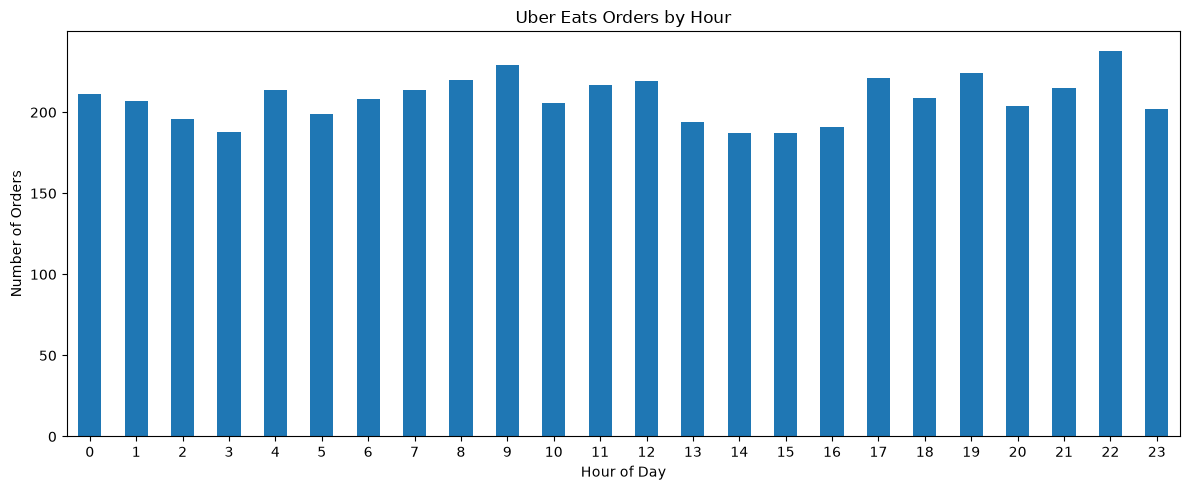

In [101]:
import matplotlib.pyplot as plt

hourly_orders.plot(kind="bar", figsize=(12, 5))

plt.title("Uber Eats Orders by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

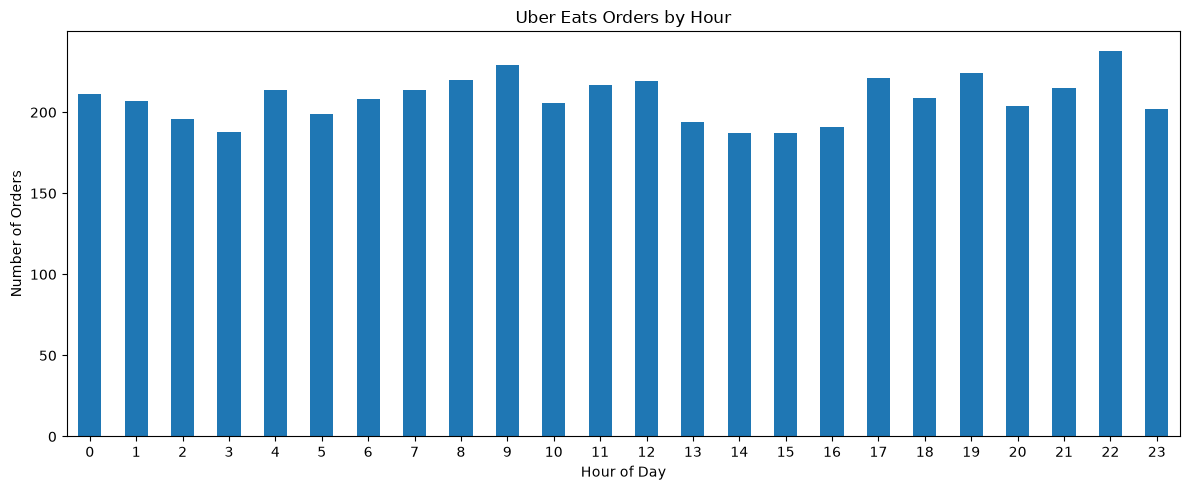

In [102]:
import matplotlib.pyplot as plt

hourly_orders.plot(kind="bar", figsize=(12, 5))

plt.title("Uber Eats Orders by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [103]:
# Extract day of the week

orders["order_day"] = orders["order_timestamp"].dt.day_name()

# Count orders by day

daily_orders = orders["order_day"].value_counts().reindex([
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
])

display(daily_orders)

order_day
Monday       677
Tuesday      757
Wednesday    690
Thursday     740
Friday       784
Saturday     671
Sunday       681
Name: count, dtype: int64

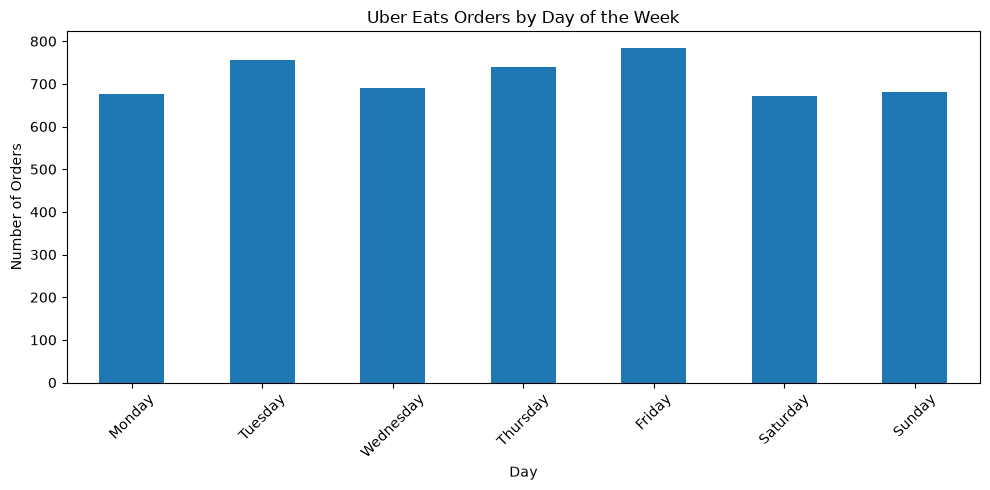

In [104]:
daily_orders.plot(kind="bar", figsize=(10, 5))

plt.title("Uber Eats Orders by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [105]:
# Count deliveries by status

delivery_status_counts = deliveries["delivery_status"].value_counts()

display(delivery_status_counts)

delivery_status
Delivered     4496
Cancelled      262
In Transit     141
Pending        101
Name: count, dtype: int64

In [106]:
# Calculate delivery metrics

print("Total Deliveries:", deliveries["delivery_id"].nunique())

print(
    "Average Delivery Time (minutes):",
    round(deliveries["delivery_time_minutes"].mean(), 2)
)

print(
    "Average Delivery Distance (km):",
    round(deliveries["delivery_distance_km"].mean(), 2)
)

print(
    "Average Preparation Time (minutes):",
    round(deliveries["preparation_time_minutes"].mean(), 2)
)

Total Deliveries: 5000
Average Delivery Time (minutes): 61.92
Average Delivery Distance (km): 7.97
Average Preparation Time (minutes): 26.27


In [107]:
# Compare average delivery time by status

delivery_time_by_status = deliveries.groupby("delivery_status")[
    "delivery_time_minutes"
].mean().round(2)

display(delivery_time_by_status)

delivery_status
Cancelled       NaN
Delivered     61.92
In Transit      NaN
Pending         NaN
Name: delivery_time_minutes, dtype: float64

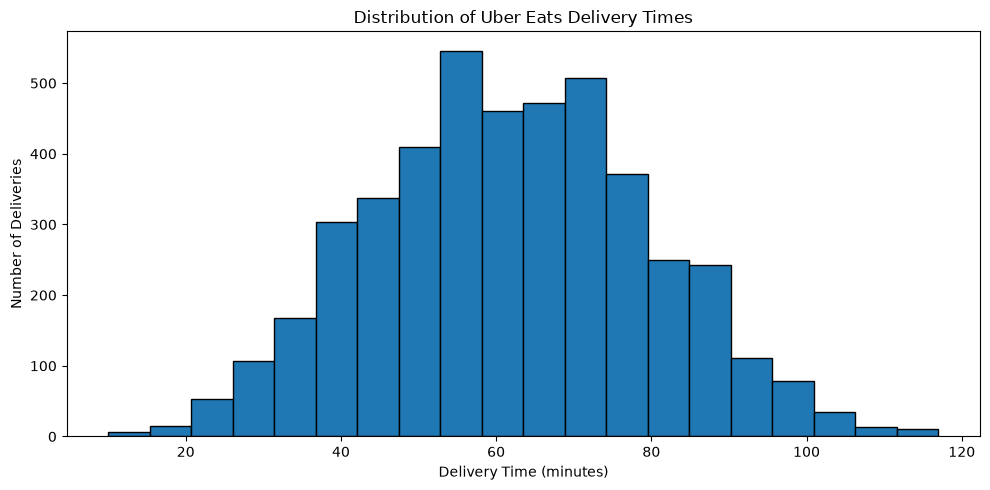

In [108]:
import matplotlib.pyplot as plt

deliveries["delivery_time_minutes"].dropna().plot(
    kind="hist",
    bins=20,
    figsize=(10, 5),
    edgecolor="black"
)

plt.title("Distribution of Uber Eats Delivery Times")
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Number of Deliveries")
plt.tight_layout()
plt.show()

In [109]:
# Merge orders and deliveries

delivery_analysis = orders[
    ["order_id", "weather", "traffic_condition"]
].merge(
    deliveries[
        ["order_id", "delivery_time_minutes", "delivery_distance_km"]
    ],
    on="order_id",
    how="left"
)

# Average delivery time by weather

weather_analysis = delivery_analysis.groupby("weather").agg(
    average_delivery_time=("delivery_time_minutes", "mean"),
    total_orders=("order_id", "count")
).round(2)

display(weather_analysis)

,average_delivery_time,total_orders
weather,,
Clear,58.04,2553
Cloudy,61.69,1175
Rainy,68.60,1049
Stormy,76.42,223


In [110]:
# Average delivery time by traffic condition

traffic_analysis = delivery_analysis.groupby("traffic_condition").agg(
    average_delivery_time=("delivery_time_minutes", "mean"),
    total_orders=("order_id", "count")
).round(2)

display(traffic_analysis)

,average_delivery_time,total_orders
traffic_condition,,
High,72.15,1248
Low,53.33,1503
Medium,61.88,2249


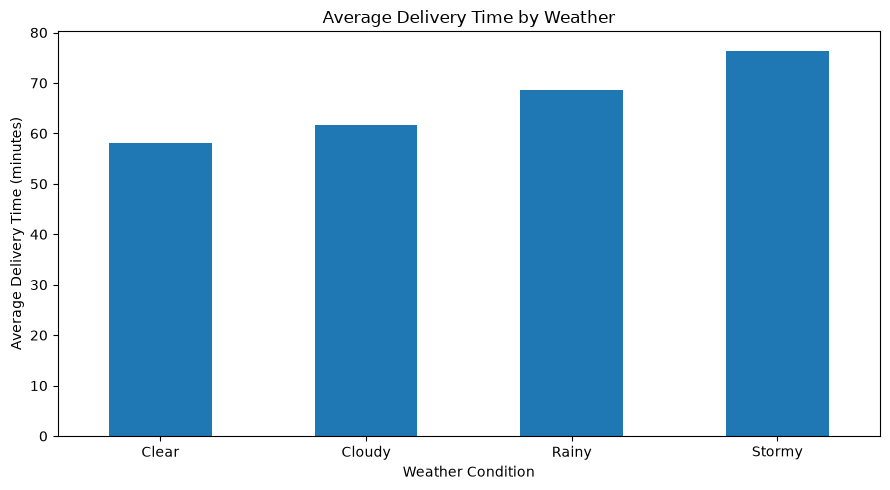

In [111]:
import matplotlib.pyplot as plt

weather_analysis["average_delivery_time"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Delivery Time by Weather")
plt.xlabel("Weather Condition")
plt.ylabel("Average Delivery Time (minutes)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

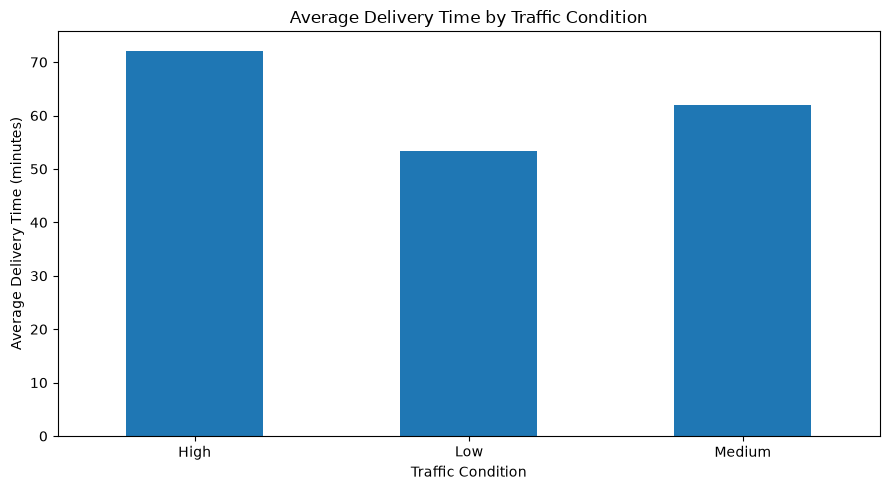

In [112]:
traffic_analysis["average_delivery_time"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Delivery Time by Traffic Condition")
plt.xlabel("Traffic Condition")
plt.ylabel("Average Delivery Time (minutes)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [113]:
# Summary of restaurant ratings

print("Average Restaurant Rating:",
      round(restaurants["restaurant_rating"].mean(), 2))

print("Highest Restaurant Rating:",
      restaurants["restaurant_rating"].max())

print("Lowest Restaurant Rating:",
      restaurants["restaurant_rating"].min())

Average Restaurant Rating: 3.83
Highest Restaurant Rating: 5.0
Lowest Restaurant Rating: 2.5


In [114]:
# Count orders for each restaurant

restaurant_orders = orders.groupby("restaurant_id").agg(
    total_orders=("order_id", "count"),
    total_order_amount=("order_amount", "sum")
).reset_index()

# Add restaurant details

restaurant_performance = restaurant_orders.merge(
    restaurants,
    on="restaurant_id",
    how="left"
)

# Display the top 10 restaurants by order volume

top_restaurants = restaurant_performance.sort_values(
    "total_orders", ascending=False
).head(10)

display(
    top_restaurants[
        ["restaurant_name", "category", "total_orders",
         "total_order_amount", "restaurant_rating"]
    ]
)

,restaurant_name,category,total_orders,total_order_amount,restaurant_rating
86,Restaurant_087,Italian,67,56949.40,3.1
36,Restaurant_037,Chinese,66,54234.60,2.5
76,Restaurant_077,Healthy,65,51430.03,3.3
14,Restaurant_015,Desserts,64,49378.70,4.0
60,Restaurant_061,Healthy,63,50667.80,4.1
66,Restaurant_067,Italian,62,49748.79,3.2
98,Restaurant_099,Italian,62,52711.85,3.3
62,Restaurant_063,Italian,62,49207.74,4.7
4,Restaurant_005,Indian,61,46839.29,4.8
2,Restaurant_003,Desserts,61,49555.13,3.1


In [115]:
# Average preparation time by restaurant category

category_preparation = restaurants.groupby("category").agg(
    average_preparation_time=("prep_time_minutes", "mean"),
    average_rating=("restaurant_rating", "mean"),
    number_of_restaurants=("restaurant_id", "count")
).round(2)

display(category_preparation)

,average_preparation_time,average_rating,number_of_restaurants
category,,,
Chinese,29.45,3.71,11
Desserts,26.79,4.18,19
Fast Food,25.79,3.86,14
Healthy,26.52,3.70,25
Indian,24.25,3.94,8
Italian,24.87,3.67,23


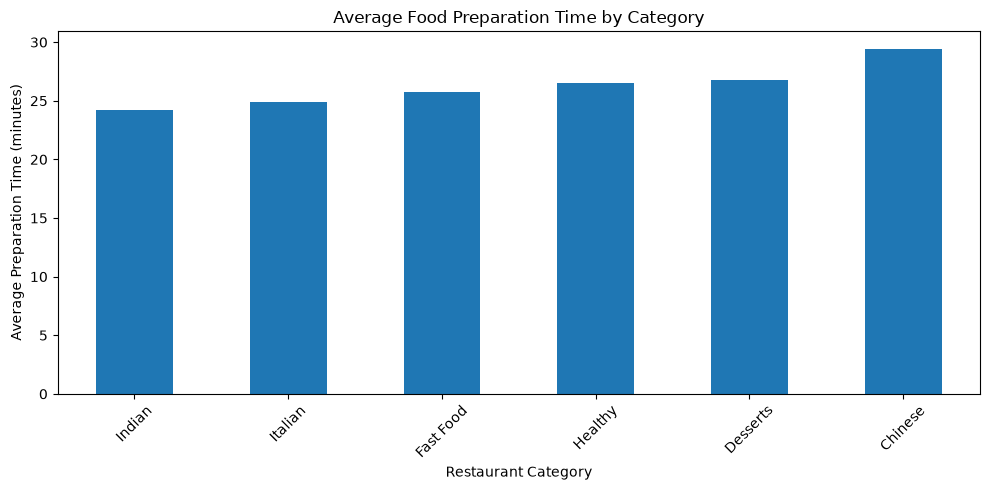

In [116]:
import matplotlib.pyplot as plt

category_preparation["average_preparation_time"].sort_values().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Food Preparation Time by Category")
plt.xlabel("Restaurant Category")
plt.ylabel("Average Preparation Time (minutes)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [117]:
# Count orders placed by each customer

customer_orders = orders.groupby("customer_id").agg(
    total_orders=("order_id", "count"),
    total_spent=("order_amount", "sum"),
    average_order_amount=("order_amount", "mean")
).reset_index()

display(customer_orders.head())

,customer_id,total_orders,total_spent,average_order_amount
0,C0001,6,4411.97,735.328333
1,C0002,4,3211.65,802.912500
2,C0003,2,2317.66,1158.830000
3,C0004,6,5066.66,844.443333
4,C0006,5,3296.68,659.336000


In [118]:
# Identify repeat customers

repeat_customers = customer_orders[
    customer_orders["total_orders"] > 1
]

print("Total Customers Who Ordered:",
      customer_orders["customer_id"].nunique())

print("Repeat Customers:",
      repeat_customers["customer_id"].nunique())

print("Repeat Customer Percentage:",
      round(
          len(repeat_customers) / len(customer_orders) * 100, 2
      ), "%")

Total Customers Who Ordered: 991
Repeat Customers: 962
Repeat Customer Percentage: 97.07 %


In [120]:
top_customers=customer_orders.sort_values("total_spent",ascending=False).head(10)
display(top_customers)

,customer_id,total_orders,total_spent,average_order_amount
670,C0677,11,13298.71,1208.973636
518,C0524,13,12486.49,960.499231
362,C0368,13,11561.92,889.378462
955,C0965,15,11365.68,757.712000
25,C0027,11,10500.96,954.632727
424,C0430,9,10478.61,1164.290000
175,C0179,10,10171.48,1017.148000
791,C0799,11,10159.75,923.613636
645,C0652,10,9909.24,990.924000
114,C0117,9,9647.00,1071.888889


In [124]:
#add customer city to order data
customer_city_analysis=customer_orders.merge(
    customers[["customer_id","city"]],
    on ="customer_id",
    how="left"
)
#summarize the customer activity by city 
city_performance=customer_city_analysis.groupby("city").agg(
    total_cutomers=("customer_id","nunique"),
    total_orders=("total_orders","sum"),
    average_customer_spending=("total_spent","mean")

).round(2)
display(city_performance)

,total_cutomers,total_orders,average_customer_spending
city,,,
Bengaluru,198,1005,4153.20
Delhi,186,942,4157.10
Hyderabad,226,1120,4131.28
Mumbai,179,922,4204.42
Pune,202,1011,4129.25


PAYMENT ANALYSIS

In [125]:
# Count transactions by payment method

payment_method_counts = payments["payment_method"].value_counts()

display(payment_method_counts)

payment_method
UPI       1316
Card      1246
Cash      1221
Wallet    1217
Name: count, dtype: int64

In [127]:
payment_status_counts=payments["payment_status"].value_counts()
display(payment_status_counts)


payment_status
Completed    4144
Refunded      494
Failed        212
Pending       150
Name: count, dtype: int64

In [128]:
# Calculate payment success rate

total_payments = len(payments)

successful_payments = (
    payments["payment_status"] == "Completed"
).sum()

payment_success_rate = (
    successful_payments / total_payments * 100
)

print("Total Transactions:", total_payments)
print("Successful Transactions:", successful_payments)
print("Payment Success Rate:", round(payment_success_rate, 2), "%")

Total Transactions: 5000
Successful Transactions: 4144
Payment Success Rate: 82.88 %


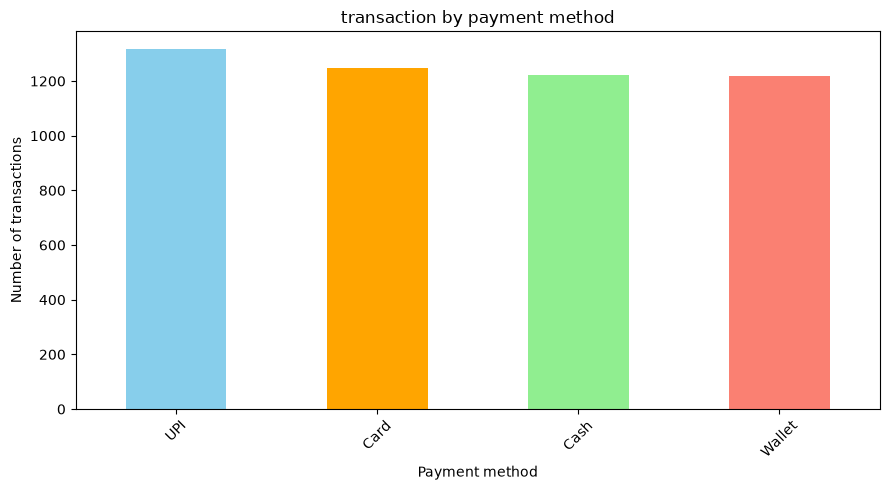

In [136]:
import matplotlib.pyplot as plt
payment_method_counts.plot(
    kind="bar",
    figsize=(9,5),
    color=["skyblue","orange","Lightgreen","salmon","violet"]
)
plt.title("transaction by payment method")
plt.xlabel("Payment method")
plt.ylabel("Number of transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


CUSTOMER REVIEW AND RATING ANALYSIS

In [8]:
orders["order_hour"] = orders["order_timestamp"].dt.hour
orders["order_day"] = orders["order_timestamp"].dt.day_name()
orders["order_month"] = orders["order_timestamp"].dt.month

display(orders[[
    "order_timestamp",
    "order_hour",
    "order_day",
    "order_month"
]].head())

,order_timestamp,order_hour,order_day,order_month
0,2025-08-19 23:00:00,23,Tuesday,8
1,2025-10-29 16:00:00,16,Wednesday,10
2,2025-07-15 03:00:00,3,Tuesday,7
3,2025-03-20 09:00:00,9,Thursday,3
4,2025-12-30 01:00:00,1,Tuesday,12


In [5]:
import pandas as pd

DATA_DIR = "uber_eats_ml_case_study/data/raw"

customers = pd.read_csv(f"{DATA_DIR}/customers.csv")
restaurants = pd.read_csv(f"{DATA_DIR}/restaurants.csv")
drivers = pd.read_csv(f"{DATA_DIR}/drivers.csv")
orders = pd.read_csv(f"{DATA_DIR}/orders.csv")
deliveries = pd.read_csv(f"{DATA_DIR}/deliveries.csv")
payments = pd.read_csv(f"{DATA_DIR}/payments.csv")
reviews = pd.read_csv(f"{DATA_DIR}/reviews.csv")

print("All seven datasets loaded successfully!")

All seven datasets loaded successfully!


In [7]:
orders["order_timestamp"] = pd.to_datetime(
    orders["order_timestamp"],
    errors="coerce"
)

print(orders["order_timestamp"].dtype)

datetime64[us]
